In [1]:
%load_ext autoreload
%autoreload 2
import warnings
warnings.filterwarnings('ignore')

In [2]:
### setup ###

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# setup path to python virtual env & code directory
ecf_env_path = '/Users/kszczepaniak/Code/ecf-explorer-env'
lib_ecf_path = ecf_env_path + '/ecf-explorer/src'
sys.path.append(lib_ecf_path)

from utils.postprocess import load_clustering_results
# from ecfs.msa import save_qecf_as_msa
from utils.postprocess import load_features_data
# from plots.plot_clustering_and_ecfs import plot_alignment_selected

workdir_path = '/Users/kszczepaniak/Data/Phage/phage-pp-workdir-ecftest-300'

In [7]:
### FIXME -> package

### load and show all-vs-all qECF table
hhr_table = pd.read_csv(workdir_path + '/ecf-explorer/input/table-ecf-hhr.txt', sep=',')

# get the slength value from the qlength (otherwise it slen is just len of aligned subject)
df_slen = hhr_table[['qname', 'qlength']]
df_slen.rename(columns = {'qname':'sname', 'qlength':'slen_true'}, inplace = True)
df_slen.drop_duplicates(inplace=True)
hhr_table = hhr_table.join(df_slen.set_index('sname'), on='sname')

### add fields to the table
# add qcov and scov
hhr_table = hhr_table.assign(qcov = lambda x: (x.qend - x.qstart + 1) / x.qlength)
hhr_table = hhr_table.assign(scov = lambda x: (x.send - x.sstart + 1) / x.slen_true)
# create prob x qcov metrics
hhr_table = hhr_table.assign(probxqcov = lambda x: x.prob * x.qcov * 0.01)
# create qcov x scov metrics
hhr_table = hhr_table.assign(qcovxscov = lambda x: x.qcov * x.scov)
# names for determining annotations
hhr_table['qname_source'] = hhr_table['qname'].apply(lambda x: x.split('_')[1])
hhr_table['sname_source'] = hhr_table['sname'].apply(lambda x: x.split('_')[1])

hhr_table

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,slen_true,qcov,scov,probxqcov,qcovxscov,qname_source,sname_source
0,ecf_reprseq00001_0,1,146,146,ecf_reprseq00001_0,1,146,146,75,380.0,5.000000e-63,100.0,1.000000e-66,146,1.000000,1.000000,1.000000,1.000000,reprseq00001,reprseq00001
1,ecf_reprseq00001_0,2,142,146,ecf_reprseq31531_0,30,157,128,13,175.9,2.800000e-25,99.8,5.800000e-29,212,0.965753,0.603774,0.963822,0.583096,reprseq00001,reprseq31531
2,ecf_reprseq00001_0,1,143,146,ecf_reprseq31887_0,1,160,160,14,135.8,2.500000e-19,99.5,5.300000e-23,160,0.979452,1.000000,0.974555,0.979452,reprseq00001,reprseq31887
3,ecf_reprseq00001_0,8,143,146,ecf_reprseq33687_0,1,191,191,8,130.7,4.100000e-17,99.3,8.700000e-21,262,0.931507,0.729008,0.924986,0.679076,reprseq00001,reprseq33687
4,ecf_reprseq00001_0,3,141,146,ecf_reprseq07891_0,29,229,201,8,113.0,9.800000e-14,98.9,2.100000e-17,318,0.952055,0.632075,0.941582,0.601770,reprseq00001,reprseq07891
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2398512,ecf_reprseq37310_2,121,139,162,ecf_reprseq09375_1,408,429,22,16,43.7,5.900000e-02,80.8,1.300000e-05,461,0.117284,0.047722,0.094765,0.005597,reprseq37310,reprseq09375
2398513,ecf_reprseq37310_2,2,36,162,ecf_reprseq09564_2,22,66,45,6,40.2,8.400000e-02,78.3,1.800000e-05,266,0.216049,0.169173,0.169167,0.036550,reprseq37310,reprseq09564
2398514,ecf_reprseq37310_2,1,37,162,ecf_reprseq10308_1,18,64,47,6,39.5,1.300000e-01,74.6,2.700000e-05,288,0.228395,0.163194,0.170383,0.037273,reprseq37310,reprseq10308
2398515,ecf_reprseq37310_2,108,140,162,ecf_reprseq21032_2,254,298,45,18,38.9,2.000000e-01,69.8,4.100000e-05,318,0.203704,0.141509,0.142185,0.028826,reprseq37310,reprseq21032


In [8]:
# debug
hhr_table[hhr_table['qname'] == 'ecf_reprseq31531_0']

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,slen_true,qcov,scov,probxqcov,qcovxscov,qname_source,sname_source
2051659,ecf_reprseq31531_0,1,212,212,ecf_reprseq31531_0,1,212,212,73,545.0,5.700000e-84,100.0,1.200000e-87,212,1.000000,1.000000,1.000000,1.000000,reprseq31531,reprseq31531
2051660,ecf_reprseq31531_0,30,205,212,ecf_reprseq12963_1,15,170,156,20,297.0,4.000000e-44,100.0,7.900000e-48,193,0.830189,0.808290,0.830189,0.671033,reprseq31531,reprseq12963
2051661,ecf_reprseq31531_0,30,205,212,ecf_reprseq29185_0,26,259,234,12,244.4,4.100000e-34,99.9,8.700000e-38,263,0.830189,0.889734,0.829358,0.738647,reprseq31531,reprseq29185
2051662,ecf_reprseq31531_0,32,205,212,ecf_reprseq10179_0,1,239,239,13,236.3,3.300000e-33,99.9,7.100000e-37,242,0.820755,0.987603,0.819934,0.810580,reprseq31531,reprseq10179
2051663,ecf_reprseq31531_0,31,205,212,ecf_reprseq04328_0,2,199,198,14,226.8,2.300000e-32,99.9,4.700000e-36,201,0.825472,0.985075,0.824646,0.813151,reprseq31531,reprseq04328
2051664,ecf_reprseq31531_0,31,205,212,ecf_reprseq20674_0,2,148,147,15,212.5,2.700000e-31,99.9,5.400000e-35,149,0.825472,0.986577,0.824646,0.814392,reprseq31531,reprseq20674
2051665,ecf_reprseq31531_0,26,205,212,ecf_reprseq33783_0,17,169,153,21,218.8,7.500000e-31,99.9,1.500000e-34,211,0.849057,0.725118,0.848208,0.615667,reprseq31531,reprseq33783
2051666,ecf_reprseq31531_0,30,200,212,ecf_reprseq24942_0,18,250,233,13,219.7,2.800000e-30,99.9,6.100000e-34,259,0.806604,0.899614,0.805797,0.725632,reprseq31531,reprseq24942
2051667,ecf_reprseq31531_0,30,205,212,ecf_reprseq20051_0,21,255,235,13,216.2,1.300000e-29,99.9,2.700000e-33,261,0.830189,0.900383,0.829358,0.747488,reprseq31531,reprseq20051
2051668,ecf_reprseq31531_0,4,205,212,ecf_reprseq06056_0,1,321,321,17,220.8,1.600000e-29,99.9,3.200000e-33,325,0.952830,0.987692,0.951877,0.941103,reprseq31531,reprseq06056


In [9]:
### FIXME -> package

### apply filters
hhr_table = hhr_table[hhr_table['sname'] != hhr_table['qname']]
hhr_table = hhr_table[hhr_table.prob >= 95.0]
hhr_table = hhr_table[hhr_table.qcov >= 0.7]
# hhr_table = hhr_table[hhr_table.probxqcov >= 0.9]

hhr_table

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,slen_true,qcov,scov,probxqcov,qcovxscov,qname_source,sname_source
1,ecf_reprseq00001_0,2,142,146,ecf_reprseq31531_0,30,157,128,13,175.9,2.800000e-25,99.8,5.800000e-29,212,0.965753,0.603774,0.963822,0.583096,reprseq00001,reprseq31531
2,ecf_reprseq00001_0,1,143,146,ecf_reprseq31887_0,1,160,160,14,135.8,2.500000e-19,99.5,5.300000e-23,160,0.979452,1.000000,0.974555,0.979452,reprseq00001,reprseq31887
3,ecf_reprseq00001_0,8,143,146,ecf_reprseq33687_0,1,191,191,8,130.7,4.100000e-17,99.3,8.700000e-21,262,0.931507,0.729008,0.924986,0.679076,reprseq00001,reprseq33687
4,ecf_reprseq00001_0,3,141,146,ecf_reprseq07891_0,29,229,201,8,113.0,9.800000e-14,98.9,2.100000e-17,318,0.952055,0.632075,0.941582,0.601770,reprseq00001,reprseq07891
5,ecf_reprseq00001_0,3,142,146,ecf_reprseq33114_0,10,230,221,8,105.8,1.200000e-12,98.7,2.700000e-16,309,0.958904,0.715210,0.946438,0.685818,reprseq00001,reprseq33114
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2398476,ecf_reprseq37310_2,1,160,162,ecf_reprseq07641_0,121,223,103,12,66.6,4.800000e-06,96.5,9.500000e-10,273,0.987654,0.377289,0.953086,0.372631,reprseq37310,reprseq07641
2398477,ecf_reprseq37310_2,1,160,162,ecf_reprseq34310_0,125,227,103,10,66.6,4.900000e-06,96.5,9.800000e-10,277,0.987654,0.371841,0.953086,0.367251,reprseq37310,reprseq34310
2398478,ecf_reprseq37310_2,1,150,162,ecf_reprseq13488_2,20,165,146,14,62.1,6.400000e-06,96.4,1.300000e-09,171,0.925926,0.853801,0.892593,0.790557,reprseq37310,reprseq13488
2398481,ecf_reprseq37310_2,2,150,162,ecf_reprseq15860_1,81,200,120,10,62.8,9.900000e-06,96.2,2.100000e-09,219,0.919753,0.547945,0.884802,0.503974,reprseq37310,reprseq15860


In [10]:
# load phrogs data & add annotations
features_to_load = ['all.annotations.table']
annot_column = 'phrog.annot.cov.0.8'

features_data = load_features_data(workdir_path, features_to_load, sep='\t')
for fname, fdata in features_data.items():
    print(fname)
#     display(fdata)
df = features_data['all.annotations.table'][['qname', annot_column]]
# get only those annotations that have 10+ occurances
df = df.groupby(annot_column).filter(lambda x: len(x) >= 10)
display(df[annot_column].value_counts())

# add qname annotations
df.rename(columns = {'qname':'qname_source', annot_column:'q_' + annot_column}, inplace = True)
hhr_table = hhr_table.join(df.set_index('qname_source'), on='qname_source')
# add sname annotations
df.rename(columns = {'qname_source':'sname_source', 'q_' + annot_column:'s_' + annot_column}, inplace = True)
hhr_table = hhr_table.join(df.set_index('sname_source'), on='sname_source')
# fill NaN with Unknown
hhr_table['q_' + annot_column].fillna('Unknown', inplace=True)
hhr_table['s_' + annot_column].fillna('Unknown', inplace=True)
hhr_table

all.annotations.table


virion structural protein                         374
tail protein                                      196
tail fiber protein                                143
major head protein                                141
portal protein                                    123
minor tail protein                                108
tail length tape measure protein                   81
baseplate protein                                  75
baseplate wedge subunit                            56
tail sheath                                        45
tail terminator                                    44
tail completion or neck1 protein                   40
tail tube protein                                  38
major tail protein                                 37
head-tail adaptor                                  36
minor head protein                                 27
head-tail adaptor ad1                              24
tail protein| virion structural protein            21
head protein                

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,...,pval,slen_true,qcov,scov,probxqcov,qcovxscov,qname_source,sname_source,q_phrog.annot.cov.0.8,s_phrog.annot.cov.0.8
1,ecf_reprseq00001_0,2,142,146,ecf_reprseq31531_0,30,157,128,13,175.9,...,5.800000e-29,212,0.965753,0.603774,0.963822,0.583096,reprseq00001,reprseq31531,Unknown,Unknown
2,ecf_reprseq00001_0,1,143,146,ecf_reprseq31887_0,1,160,160,14,135.8,...,5.300000e-23,160,0.979452,1.000000,0.974555,0.979452,reprseq00001,reprseq31887,Unknown,Unknown
3,ecf_reprseq00001_0,8,143,146,ecf_reprseq33687_0,1,191,191,8,130.7,...,8.700000e-21,262,0.931507,0.729008,0.924986,0.679076,reprseq00001,reprseq33687,Unknown,Unknown
4,ecf_reprseq00001_0,3,141,146,ecf_reprseq07891_0,29,229,201,8,113.0,...,2.100000e-17,318,0.952055,0.632075,0.941582,0.601770,reprseq00001,reprseq07891,Unknown,major head protein
5,ecf_reprseq00001_0,3,142,146,ecf_reprseq33114_0,10,230,221,8,105.8,...,2.700000e-16,309,0.958904,0.715210,0.946438,0.685818,reprseq00001,reprseq33114,Unknown,Unknown
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2398476,ecf_reprseq37310_2,1,160,162,ecf_reprseq07641_0,121,223,103,12,66.6,...,9.500000e-10,273,0.987654,0.377289,0.953086,0.372631,reprseq37310,reprseq07641,Unknown,Unknown
2398477,ecf_reprseq37310_2,1,160,162,ecf_reprseq34310_0,125,227,103,10,66.6,...,9.800000e-10,277,0.987654,0.371841,0.953086,0.367251,reprseq37310,reprseq34310,Unknown,Unknown
2398478,ecf_reprseq37310_2,1,150,162,ecf_reprseq13488_2,20,165,146,14,62.1,...,1.300000e-09,171,0.925926,0.853801,0.892593,0.790557,reprseq37310,reprseq13488,Unknown,Unknown
2398481,ecf_reprseq37310_2,2,150,162,ecf_reprseq15860_1,81,200,120,10,62.8,...,2.100000e-09,219,0.919753,0.547945,0.884802,0.503974,reprseq37310,reprseq15860,Unknown,Unknown


,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,...,pval,slen_true,qcov,scov,probxqcov,qcovxscov,qname_source,sname_source,q_phrog.annot.cov.0.8,s_phrog.annot.cov.0.8
2,ecf_reprseq00001_0,1,143,146,ecf_reprseq31887_0,1,160,160,14,135.8,...,5.300000e-23,160,0.979452,1.000000,0.974555,0.979452,reprseq00001,reprseq31887,Unknown,Unknown
25,ecf_reprseq00017_0,1,693,693,ecf_reprseq34686_0,5,773,769,26,1463.3,...,5.000000e-189,774,1.000000,0.993540,1.000000,0.993540,reprseq00017,reprseq34686,major head protein,major head protein
26,ecf_reprseq00017_0,1,693,693,ecf_reprseq30921_0,5,616,612,47,1396.8,...,7.000000e-184,616,1.000000,0.993506,1.000000,0.993506,reprseq00017,reprseq30921,major head protein,major head protein
27,ecf_reprseq00017_0,1,693,693,ecf_reprseq16101_0,5,892,888,17,1300.1,...,3.000000e-166,895,1.000000,0.992179,1.000000,0.992179,reprseq00017,reprseq16101,major head protein,major head protein
28,ecf_reprseq00017_0,1,693,693,ecf_reprseq16162_0,5,899,895,24,1294.3,...,9.000000e-166,900,1.000000,0.994444,1.000000,0.994444,reprseq00017,reprseq16162,major head protein,major head protein
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2398248,ecf_reprseq37310_1,7,166,167,ecf_reprseq04241_2,2,182,181,16,121.5,...,9.700000e-20,183,0.958084,0.989071,0.950419,0.947613,reprseq37310,reprseq04241,Unknown,Unknown
2398250,ecf_reprseq37310_1,7,166,167,ecf_reprseq02094_3,3,172,170,14,118.6,...,2.300000e-19,173,0.958084,0.982659,0.950419,0.941470,reprseq37310,reprseq02094,Unknown,Unknown
2398260,ecf_reprseq37310_1,12,155,167,ecf_reprseq15569_3,1,106,106,9,96.8,...,1.400000e-16,109,0.862275,0.972477,0.851928,0.838543,reprseq37310,reprseq15569,Unknown,Unknown
2398406,ecf_reprseq37310_2,1,161,162,ecf_reprseq29575_2,1,146,146,35,195.7,...,2.600000e-33,146,0.993827,1.000000,0.992833,0.993827,reprseq37310,reprseq29575,Unknown,Unknown


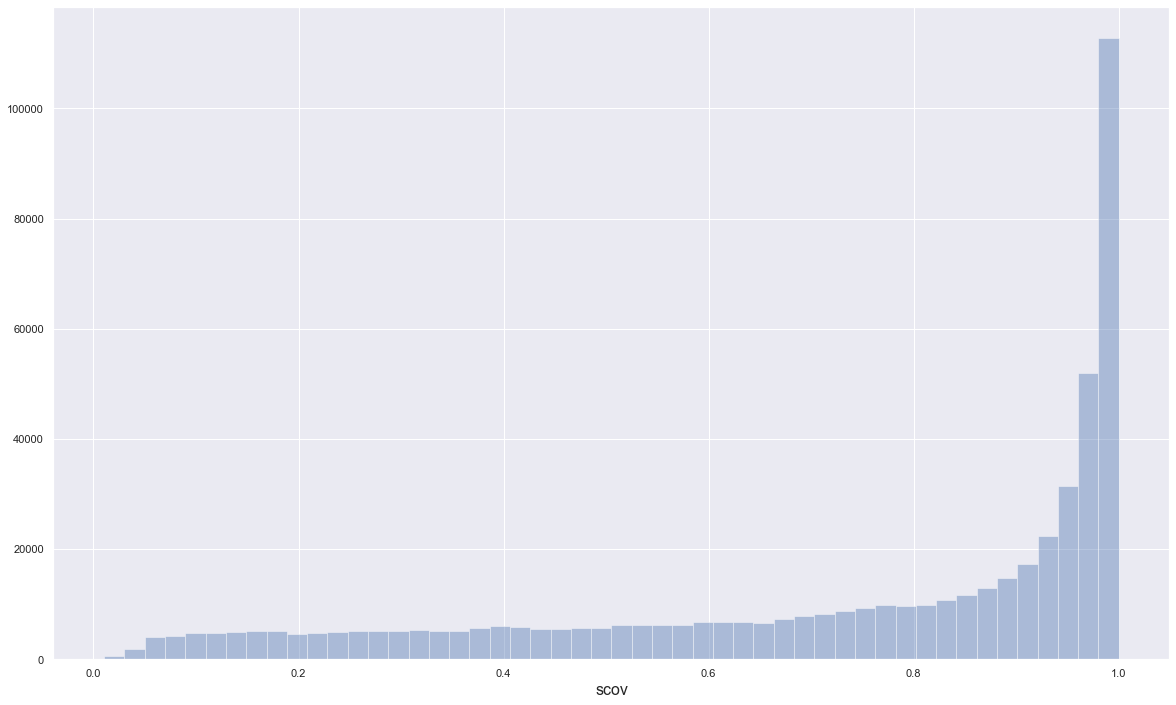

In [20]:
### how many qECFs are contained within other qECFs
# i.e. how often most/entire subject is within the query (highest scov)

sns.set(rc={"figure.figsize":(20, 12), "axes.labelsize":16})
sns.distplot(hhr_table['scov'], kde=False)
hhr_table[hhr_table['scov'] >= 0.95]

In [12]:
### qECFs clustering by qcov*scov


In [6]:
### add annotations and select only interactions with known annotations
hhr_table = hhr_table[(hhr_table['q_' + annot_column] != 'Unknown') | (hhr_table['s_' + annot_column] != 'Unknown')]
hhr_table

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,qcov,probxqcov,qname_source,sname_source,q_phrog.annot.cov.0.8,s_phrog.annot.cov.0.8
4,ecf_reprseq00001_0,3,141,146,ecf_reprseq07891_0,29,229,201,8,113.0,9.800000e-14,98.9,2.100000e-17,0.952055,0.941582,reprseq00001,reprseq07891,Unknown,major head protein
16,ecf_reprseq00001_0,16,143,146,ecf_reprseq19273_2,2,151,150,10,61.8,9.500000e-06,96.2,2.000000e-09,0.876712,0.843397,reprseq00001,reprseq19273,Unknown,major head protein
25,ecf_reprseq00017_0,1,693,693,ecf_reprseq34686_0,5,773,769,26,1463.3,2.000000e-185,100.0,5.000000e-189,1.000000,1.000000,reprseq00017,reprseq34686,major head protein,major head protein
26,ecf_reprseq00017_0,1,693,693,ecf_reprseq30921_0,5,616,612,47,1396.8,4.000000e-180,100.0,7.000000e-184,1.000000,1.000000,reprseq00017,reprseq30921,major head protein,major head protein
27,ecf_reprseq00017_0,1,693,693,ecf_reprseq16101_0,5,892,888,17,1300.1,1.000000e-162,100.0,3.000000e-166,1.000000,1.000000,reprseq00017,reprseq16101,major head protein,major head protein
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2397156,ecf_reprseq37305_1,3,326,327,ecf_reprseq16687_1,5,481,477,6,132.6,3.900000e-14,99.0,8.300000e-18,0.990826,0.980917,reprseq37305,reprseq16687,Unknown,major head protein
2397157,ecf_reprseq37305_1,3,327,327,ecf_reprseq16687_0,7,275,269,8,131.0,9.000000e-14,98.9,1.900000e-17,0.993884,0.982951,reprseq37305,reprseq16687,Unknown,major head protein
2397158,ecf_reprseq37305_1,4,327,327,ecf_reprseq33451_0,10,275,266,7,124.2,8.900000e-13,98.7,1.900000e-16,0.990826,0.977945,reprseq37305,reprseq33451,Unknown,major head protein
2397162,ecf_reprseq37305_1,3,326,327,ecf_reprseq33298_0,6,324,319,9,114.8,2.700000e-11,98.4,5.800000e-15,0.990826,0.974972,reprseq37305,reprseq33298,Unknown,major head protein


In [53]:
# heatmap: phrogs by phrogs and number of connected qECFs
# need table: phrog1,phrgos2,nb-connections
sns.set(rc={"figure.figsize":(20, 12), "axes.labelsize":16})
hhr_qecf_pairs = hhr_table[['q_phrog.annot.cov.0.8', 's_phrog.annot.cov.0.8']]
hhr_qecf_pairs_size = hhr_qecf_pairs.groupby(hhr_qecf_pairs.columns.tolist(),as_index=False).size()
hhr_qecf_pairs_size = hhr_qecf_pairs_size.pivot('q_phrog.annot.cov.0.8', 's_phrog.annot.cov.0.8', 'size')
hhr_qecf_pairs_size

s_phrog.annot.cov.0.8,Unknown,baseplate hub,baseplate hub subunit and tail lysozyme,baseplate hub| tail protein,baseplate protein,baseplate tail tube cap,baseplate wedge subunit,head closure hc1,head closure hc2,head decoration,...,tail completion or neck1 protein,tail fiber protein,tail length tape measure protein,tail protein,tail protein| virion structural protein,tail sheath,tail spike protein,tail terminator,tail tube protein,virion structural protein
q_phrog.annot.cov.0.8,,,,,,,,,,,,,,,,,,,,,
Unknown,NaN,97.0,745.0,25.0,2386.0,49.0,1744.0,70.0,74.0,27.0,...,304.0,1135.0,112.0,1186.0,90.0,498.0,60.0,78.0,5042.0,735.0
baseplate hub,83.0,433.0,NaN,NaN,21.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
baseplate hub subunit and tail lysozyme,382.0,NaN,266.0,NaN,9.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
baseplate hub| tail protein,13.0,NaN,NaN,114.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,92.0,1.0,NaN,NaN,NaN,NaN,NaN
baseplate protein,2396.0,21.0,19.0,NaN,3279.0,NaN,2090.0,NaN,NaN,NaN,...,NaN,NaN,NaN,33.0,6.0,2.0,NaN,NaN,NaN,2.0
baseplate tail tube cap,37.0,NaN,NaN,NaN,NaN,146.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
baseplate wedge subunit,1670.0,NaN,NaN,NaN,2077.0,NaN,2830.0,NaN,NaN,NaN,...,NaN,NaN,NaN,2.0,NaN,1.0,NaN,NaN,NaN,30.0
head closure hc1,71.0,NaN,NaN,NaN,NaN,NaN,NaN,130.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
head closure hc2,80.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,40.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0


<AxesSubplot:xlabel='s_phrog.annot.cov.0.8', ylabel='q_phrog.annot.cov.0.8'>

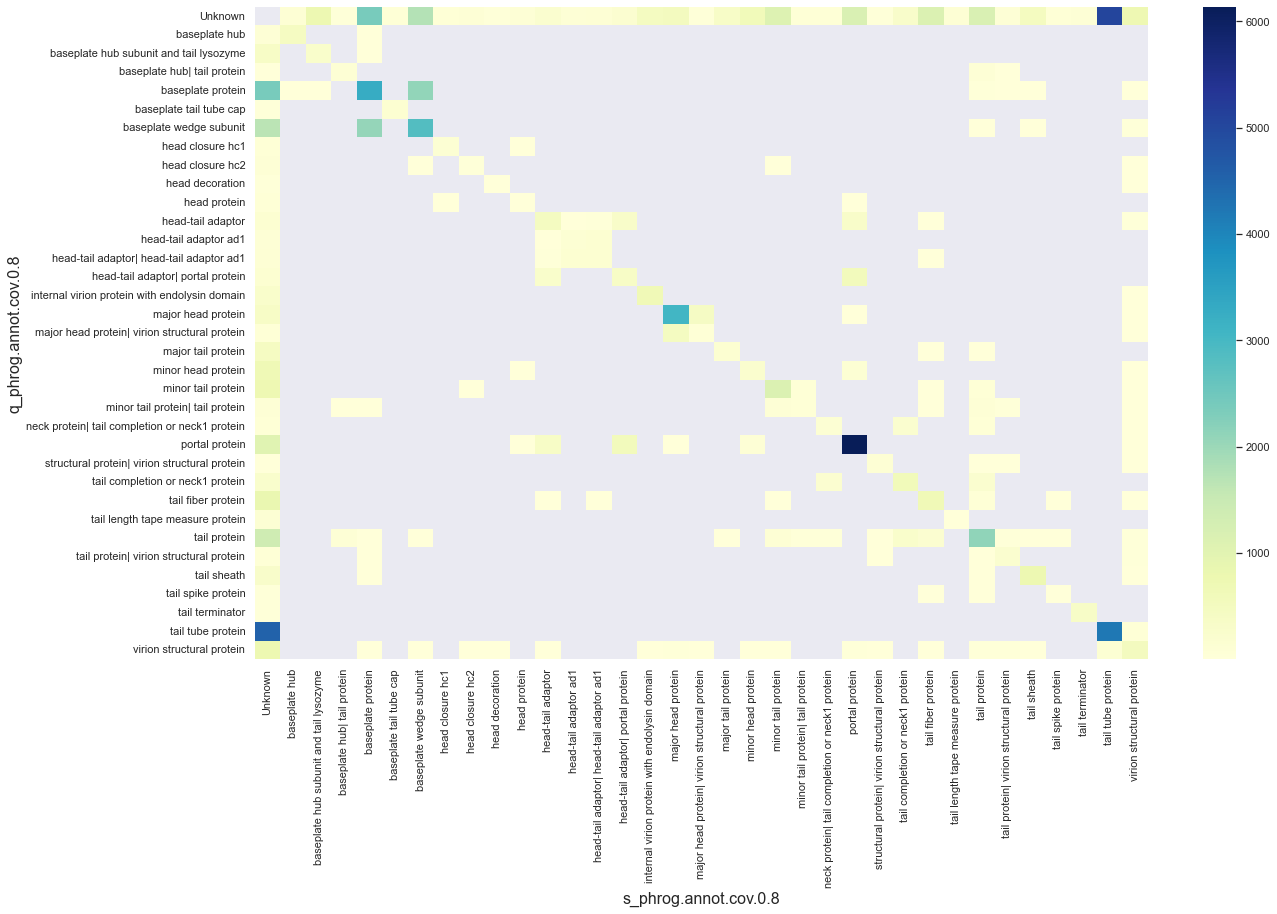

In [26]:
sns.heatmap(hhr_qecf_pairs_size, cmap="YlGnBu")

In [51]:
# heatmap: phrogs by phrogs and nb of phrogs comprising 
# hist: diversity (avg nb of phrogs per qECF)
clustering_results = load_clustering_results(workdir_path, mode='clusters')

df = features_data['all.annotations.table'][['qname', annot_column]]
# get only those annotations that have 10+ occurances
df = df.groupby(annot_column).filter(lambda x: len(x) >= 10)

# add qname annotations
df.rename(columns = {annot_column:'q_' + annot_column}, inplace = True)
clustering_results = clustering_results.join(df.set_index('qname'), on='qname')

# add sname annotations
df.rename(columns = {'qname':'sname', 'q_' + annot_column:'s_' + annot_column}, inplace = True)
clustering_results = clustering_results.join(df.set_index('sname'), on='sname')
# fill NaN with Unknown
clustering_results['q_' + annot_column].fillna('Unknown', inplace=True)
clustering_results['s_' + annot_column].fillna('Unknown', inplace=True)
clustering_results = clustering_results[(clustering_results['q_' + annot_column] != 'Unknown') | (clustering_results['s_' + annot_column] != 'Unknown')]

clustering_results['ecf_id'] = ('ecf_' + clustering_results['qname'] + '_' + clustering_results['cluster'].astype(str))
clustering_results

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,cluster,q_phrog.annot.cov.0.8,s_phrog.annot.cov.0.8,ecf_id
1312,reprseq03136,560,753,779,reprseq09187,541,755,781,33,86.4,7.900000e-06,96.5,9.300000e-10,0,Unknown,tail fiber protein,ecf_reprseq03136_0
1315,reprseq03136,584,657,779,reprseq25439,79,167,237,24,68.9,1.300000e-04,95.3,2.100000e-08,0,Unknown,tail protein,ecf_reprseq03136_0
1316,reprseq03136,584,779,779,reprseq21493,115,283,283,27,103.2,6.800000e-09,97.8,1.100000e-12,0,Unknown,tail protein,ecf_reprseq03136_0
1317,reprseq03136,584,656,779,reprseq05309,110,188,292,21,75.4,2.700000e-05,96.0,4.400000e-09,0,Unknown,tail fiber protein,ecf_reprseq03136_0
1324,reprseq08823,1,219,220,reprseq36598,67,270,270,29,379.2,8.000000e-56,100.0,1.200000e-59,0,Unknown,minor tail protein,ecf_reprseq08823_0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
652496,reprseq18473,74,188,655,reprseq33687,25,139,177,20,126.7,2.000000e-13,98.9,2.700000e-17,1,major head protein,Unknown,ecf_reprseq18473_1
652497,reprseq18473,85,190,655,reprseq22881,121,248,300,20,73.7,4.000000e-05,95.9,5.000000e-09,1,major head protein,Unknown,ecf_reprseq18473_1
652498,reprseq18473,86,188,655,reprseq20440,33,187,480,18,67.9,8.600000e-04,94.2,1.100000e-07,1,major head protein,Unknown,ecf_reprseq18473_1
652499,reprseq18473,86,188,655,reprseq29127,447,550,833,15,77.7,1.600000e-04,95.4,2.000000e-08,1,major head protein,portal protein,ecf_reprseq18473_1


In [91]:
ecfs_count = {qannot:{sannot:0 for sannot in clustering_results['s_' + annot_column].unique()} for qannot in clustering_results['q_' + annot_column].unique()}
for eid, ecf in clustering_results.groupby('ecf_id'):
    ecf_qannot = ecf['q_' + annot_column].to_list()[0]
    for ecf_sannot in ecf['s_' + annot_column].unique():
        ecfs_count[ecf_qannot][ecf_sannot] += 1
ecfs_counts_table = pd.DataFrame.from_dict(ecfs_count, orient='index')
ecfs_counts_table

,tail fiber protein,tail protein,minor tail protein,minor tail protein| tail protein,major head protein,Unknown,major head protein| virion structural protein,virion structural protein,tail spike protein,baseplate protein,...,major tail protein,baseplate hub,baseplate hub subunit and tail lysozyme,tail terminator,head protein,head closure hc1,tail completion or neck1 protein,neck protein| tail completion or neck1 protein,structural protein| virion structural protein,baseplate hub| tail protein
Unknown,558,527,256,66,75,0,22,556,124,156,...,89,7,81,16,62,12,46,34,5,5
major head protein,0,0,0,0,206,135,89,15,0,0,...,0,0,0,0,0,0,0,0,0,0
virion structural protein,28,21,13,1,3,127,2,109,4,1,...,0,0,0,0,1,0,1,1,2,0
minor tail protein,10,48,91,33,0,115,0,24,0,0,...,1,0,0,0,0,0,0,0,0,0
major head protein| virion structural protein,0,0,0,0,31,22,14,4,0,0,...,0,0,0,0,0,0,0,0,0,0
baseplate protein,0,9,0,0,0,149,0,7,0,138,...,0,1,4,0,0,0,0,0,0,0
tail protein,69,196,24,35,0,220,0,39,21,7,...,1,0,0,0,0,0,28,15,1,14
baseplate wedge subunit,0,0,0,0,0,94,0,7,0,52,...,0,0,0,0,0,0,0,0,0,0
portal protein,0,0,0,0,1,195,0,8,0,0,...,0,0,0,0,5,0,0,0,0,0
tail protein| virion structural protein,0,11,2,11,0,22,0,18,0,6,...,0,0,0,0,0,0,0,0,1,0


[Text(0.5, 84.453125, 'nb of qECF with Phrog'),
 Text(156.453125, 0.5, 'qECF functional class')]

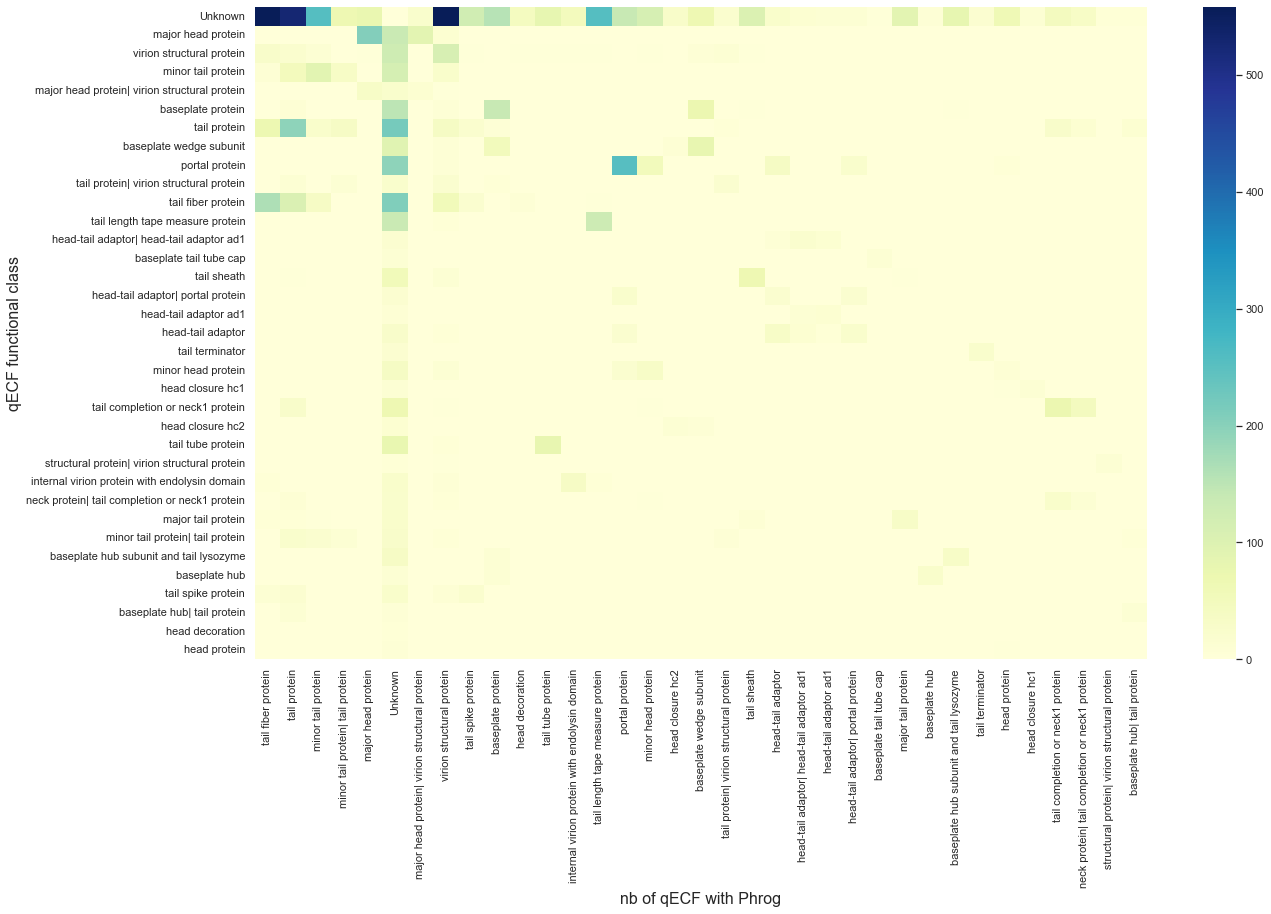

In [90]:
ax = sns.heatmap(ecfs_counts_table, cmap="YlGnBu")
ax.set(xlabel='nb of qECF with Phrog', ylabel='qECF functional class')

In [162]:
### FIXME -> package

### save to SIF file for Cytoscape
# this will consider every hit from table as an interaction in network (all of them will be equal in Cytoscape)
output_dirpath = workdir_path + '/ecf-explorer/output/'
fsif           = open(output_dirpath + 'ecf_network.sif', 'w')

for eid, ecf in hhr_table.groupby('qname'):
    row = eid + ' pp'
    for hid, hit in ecf.iterrows():
        row += ' ' + hit['sname']
    row += '\n'
    fsif.write(row)    
fsif.close()

In [163]:
### FIXME -> package

annot_ecfs_q = hhr_table[['qname', 'q_' + annot_column]]
annot_ecfs_s = hhr_table[['sname', 's_' + annot_column]]
annot_ecfs_s.rename(columns = {'sname':'qname', 's_' + annot_column:'q_' + annot_column}, inplace = True)

annot_ecfs = pd.concat([annot_ecfs_q, annot_ecfs_s])
annot_ecfs.drop_duplicates(subset=['qname'], inplace=True)

annot_ecfs = annot_ecfs.set_index('qname')
annot_ecfs.to_csv(output_dirpath + 'ecf_annot.txt')
annot_ecfs

,q_phrog.annot.cov.0.8
qname,
ecf_reprseq00001_0,Unknown
ecf_reprseq00017_0,major head protein
ecf_reprseq00018_0,baseplate tail tube cap
ecf_reprseq00022_0,Unknown
ecf_reprseq00022_1,Unknown
...,...
ecf_reprseq36109_3,Unknown
ecf_reprseq05573_0,Unknown
ecf_reprseq29170_0,Unknown


In [164]:
annot_ecfs['q_'+annot_column].value_counts()

Unknown                                           1757
portal protein                                     247
tail protein                                       201
major head protein                                 197
baseplate protein                                  144
virion structural protein                          120
minor tail protein                                 118
baseplate wedge subunit                            103
tail fiber protein                                 102
tail tube protein                                   84
tail completion or neck1 protein                    78
tail sheath                                         50
head-tail adaptor                                   41
internal virion protein with endolysin domain       40
minor head protein                                  36
major tail protein                                  34
major head protein| virion structural protein       31
neck protein| tail completion or neck1 protein      26
minor tail